<a href="https://colab.research.google.com/github/teddiclax/METHANE__PYROLYSIS__H2/blob/teddiclax/METHANE__PYROLYSIS__H2__UPDATED.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
### DATA PREPARATION (ETHICAL TRAIN-ONLY AUGMENTATION) ###
## Importing Necessary Libraries ##
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import torch.nn.functional as F
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import os
import time

# -----------------------------
# 1) Loading Original Dataset
# -----------------------------
raw_df = pd.read_csv('/content/METHANE__REFORMING__SMR.csv')
raw_df.columns = [col.strip() for col in raw_df.columns]

# Defining Input Variables
feature_cols = ['T(C)', 'P(bar)', 'F(mL/h)', 'Y(%)', 'p(W)', 'TOS(h)']
target_col = 'MoH(g)'

# -----------------------------
# 2) Clean NaNs (no change)
# -----------------------------
initial_rows_count = len(raw_df)
raw_df_cleaned = raw_df.dropna(subset=feature_cols + [target_col]).copy()
print(f"Dropped {initial_rows_count - len(raw_df_cleaned)} rows from raw_df due to NaNs in feature/target columns.")

X_raw = raw_df_cleaned[feature_cols].values.astype(float)
y_raw = raw_df_cleaned[[target_col]].values.astype(float)  # (N,1)

# -----------------------------
# 3) RAW split: Train / (Val+Test) first, then Val/Test split
#    (keeps Val/Test unaugmented)
# -----------------------------
SEED = 42
np.random.seed(SEED)

X_train_raw, X_tmp_raw, y_train_raw, y_tmp_raw = train_test_split(
    X_raw, y_raw, test_size=0.30, random_state=SEED
)

X_val_raw, X_test_raw, y_val_raw, y_test_raw = train_test_split(
    X_tmp_raw, y_tmp_raw, test_size=0.50, random_state=SEED
)

print("\nRAW split shapes (unaugmented):")
print("Train:", X_train_raw.shape, y_train_raw.shape)
print("Val  :", X_val_raw.shape,   y_val_raw.shape)
print("Test :", X_test_raw.shape,  y_test_raw.shape)

# -----------------------------
# 4) Log transform targets (log1p) safely for each split
# -----------------------------
eps = np.finfo(float).eps

y_train_pos = np.where(y_train_raw <= 0, eps, y_train_raw)
y_val_pos   = np.where(y_val_raw   <= 0, eps, y_val_raw)
y_test_pos  = np.where(y_test_raw  <= 0, eps, y_test_raw)

y_train_log_raw = np.log1p(y_train_pos)
y_val_log       = np.log1p(y_val_pos)
y_test_log      = np.log1p(y_test_pos)

# -----------------------------
# 5) TRAIN-ONLY augmentation (key ethical fix)
#    N_aug = 1 means "no augmentation" (original training set)
# -----------------------------
N_aug = 100          # <-- make this variable (e.g., 1, 2, 10, 100)
noise_level = 0.02 # same meaning as your code

# Repeat ONLY the training set
X_train_aug = np.repeat(X_train_raw, N_aug, axis=0)
y_train_aug = np.repeat(y_train_raw, N_aug, axis=0)

# Add noise ONLY to augmented training
# (keeps your concept: multiplicative Gaussian noise)
X_train_aug = X_train_aug * (1 + np.random.randn(*X_train_aug.shape) * noise_level)
y_train_aug = y_train_aug * (1 + np.random.randn(*y_train_aug.shape) * noise_level)

# Ensure y_train_aug strictly positive before log1p
y_train_aug_pos = np.where(y_train_aug <= 0, eps, y_train_aug)
y_train_log_aug = np.log1p(y_train_aug_pos)

# -----------------------------
# 6) Sanity checks (no change in concept)
# -----------------------------
print("\nSanity check — any NaNs in y_train_log_aug (before final filter)?", np.isnan(y_train_log_aug).sum())
print("Sanity check — any NaNs in X_train_aug (before final filter)?", np.isnan(X_train_aug).sum())

nan_mask_X = np.isnan(X_train_aug).any(axis=1)
nan_mask_y = np.isnan(y_train_log_aug).flatten()
combined_nan_mask = nan_mask_X | nan_mask_y

if np.sum(combined_nan_mask) > 0:
    print(f"Filtering {np.sum(combined_nan_mask)} rows with NaNs in TRAIN augmented data.")
    X_train_aug_filtered = X_train_aug[~combined_nan_mask]
    y_train_log_aug_filtered = y_train_log_aug[~combined_nan_mask]
else:
    X_train_aug_filtered = X_train_aug
    y_train_log_aug_filtered = y_train_log_aug

print("TRAIN augmented shapes after filtering:")
print("X_train_aug:", X_train_aug_filtered.shape)
print("y_train_log:", y_train_log_aug_filtered.shape)

# -----------------------------
# 7) Standardization
#    Fit scaler on TRAIN (augmented) only; apply to raw Val/Test
# -----------------------------
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_aug_filtered)
X_val_scaled   = scaler.transform(X_val_raw)
X_test_scaled  = scaler.transform(X_test_raw)

print(f"\nFINAL shapes:")
print(f"Train (aug): {X_train_scaled.shape}, Val (raw): {X_val_scaled.shape}, Test (raw): {X_test_scaled.shape}")

# Return targets in log-space (consistent with your original pipeline)
y_train_log = y_train_log_aug_filtered.reshape(-1, 1)
y_val_log   = y_val_log.reshape(-1, 1)
y_test_log  = y_test_log.reshape(-1, 1)

print(f"Targets (log) shapes:")
print("y_train_log:", y_train_log.shape)
print("y_val_log  :", y_val_log.shape)
print("y_test_log :", y_test_log.shape)

Dropped 13 rows from raw_df due to NaNs in feature/target columns.

RAW split shapes (unaugmented):
Train: (74, 6) (74, 1)
Val  : (16, 6) (16, 1)
Test : (16, 6) (16, 1)

Sanity check — any NaNs in y_train_log_aug (before final filter)? 0
Sanity check — any NaNs in X_train_aug (before final filter)? 0
TRAIN augmented shapes after filtering:
X_train_aug: (7400, 6)
y_train_log: (7400, 1)

FINAL shapes:
Train (aug): (7400, 6), Val (raw): (16, 6), Test (raw): (16, 6)
Targets (log) shapes:
y_train_log: (7400, 1)
y_val_log  : (16, 1)
y_test_log : (16, 1)


In [3]:
# ### DATA PREPARATION ###
# ## Importing Necessary Libraries ##
# import pandas as pd
# import numpy as np
# import torch
# import torch.nn as nn
# import torch.optim as optim
# from torch.utils.data import TensorDataset, DataLoader
# import torch.nn.functional as F
# from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
# from sklearn.model_selection import train_test_split
# from sklearn.preprocessing import StandardScaler
# import matplotlib.pyplot as plt
# import os
# import time


# ## Loading Original Dataset ##
# raw_df = pd.read_csv('/content/METHANE__REFORMING__SMR.csv')
# raw_df.columns = [col.strip() for col in raw_df.columns]

# ## Defining the Input Variables ##
# feature_cols = ['T(C)', 'P(bar)', 'F(mL/h)', 'Y(%)', 'p(W)', 'TOS(h)']

# ## efining the Feature and Target Columns in the Raw Dataset ##
# target_col = 'MoH(g)'

# # --- Start of fix for NaN values ---
# # 1. Filter out rows with NaN in feature_cols or target_col from the raw_df
# initial_rows_count = len(raw_df)
# raw_df_cleaned = raw_df.dropna(subset=feature_cols + [target_col]).copy()
# print(f"Dropped {initial_rows_count - len(raw_df_cleaned)} rows from raw_df due to NaNs in feature/target columns.")

# ## Defining the Feature and Target Columns in the Cleaned Raw Dataset ##
# X_raw = raw_df_cleaned[feature_cols].values
# y_raw = raw_df_cleaned[[target_col]].values  # The Shape of the Column (MoH) is (N,1)

# # 2. Ensure y_raw is strictly positive before log1p transformation for the raw test set
# # Replace non-positive values with a small epsilon to avoid NaN or -inf in log1p
# y_raw_positive_for_log = np.where(y_raw <= 0, np.finfo(float).eps, y_raw)
# y_raw_log = np.log1p(y_raw_positive_for_log)

# ## Generating Augmented Data for Training the Neural Networks ##
# np.random.seed(42)
# N_aug = 2 # The Original Raw Dataset is Multiplied by 100 (X 100)
# X_aug = np.repeat(X_raw, N_aug, axis=0)
# y_aug = np.repeat(y_raw, N_aug, axis=0)

# ## Adding of Noise to the Populated Raw Data ##
# noise_level = 0.02
# X_aug = X_aug * (1 + np.random.randn(*X_aug.shape) * noise_level)
# y_aug = y_aug * (1 + np.random.randn(*y_aug.shape) * noise_level)

# # 2. Ensure y_aug is strictly positive before log1p transformation
# y_aug_positive_for_log = np.where(y_aug <= 0, np.finfo(float).eps, y_aug)
# y_aug_log = np.log1p(y_aug_positive_for_log)

# ## Deploy a Sanity Check for no NaNs or formation of Negatives ##
# print("Sanity check — any NaNs in y_aug_log (before final filter)?", np.isnan(y_aug_log).sum())
# print("Sanity check — any NaNs in X_aug (before final filter)?", np.isnan(X_aug).sum())

# # 3. Filter out any remaining NaNs after noise and log1p, if any
# nan_mask_X_aug = np.isnan(X_aug).any(axis=1)
# nan_mask_y_aug_log = np.isnan(y_aug_log).flatten()
# combined_nan_mask = nan_mask_X_aug | nan_mask_y_aug_log

# if np.sum(combined_nan_mask) > 0:
#     print(f"Filtering {np.sum(combined_nan_mask)} rows with NaNs in augmented data after noise/log transform.")
#     X_aug_filtered = X_aug[~combined_nan_mask]
#     y_aug_log_filtered = y_aug_log[~combined_nan_mask]
# else:
#     X_aug_filtered = X_aug
#     y_aug_log_filtered = y_aug_log

# print(f"Shape of X_aug after filtering: {X_aug_filtered.shape}")
# print(f"Shape of y_aug_log after filtering: {y_aug_log_filtered.shape}")


# ## Splitting the Dataset in the ratio of 70:15:15 for the Training, Validation and Test Sets ##

# ## It is worth noting that the Validation and Testing dataset is still unchanged   ##
# X_train_aug, X_val_raw, y_train_log, y_val_log = train_test_split(
#     X_aug_filtered, y_aug_log_filtered, test_size=0.2, random_state=42)

# ## Final Test Datasets with no Noise ##
# X_test_raw = X_raw
# y_test_log = y_raw_log

# ## Standardization of the Argumented Training Dataset ##
# scaler = StandardScaler()
# X_train_scaled = scaler.fit_transform(X_train_aug)
# X_val_scaled = scaler.transform(X_val_raw)
# X_test_scaled = scaler.transform(X_test_raw)

# ## Displaying the Shape of the Training, Validation and Testing  ##
# print(f"\nTrain shape: {X_train_scaled.shape}, Val shape: {X_val_scaled.shape}, Test shape: {X_test_scaled.shape}")

In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')

In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')

In [4]:
### PRELIMINARY DATA ANALYSIS OF THE RAW DATASET ###

## Filtering Operating Data with MoH(g) > 0 and NAN from MoH(g) > 0 ##

df_operational = raw_df[(raw_df['MoH(g)'] > 0) & raw_df['SEC(kWh/kg H2)'].notna()].copy()

# Convert 'SEC(kWh/kg H2)' to numeric, coercing errors
df_operational['SEC(kWh/kg H2)'] = pd.to_numeric(df_operational['SEC(kWh/kg H2)'], errors='coerce')

# Drop rows where 'SEC(kWh/kg H2)' became NaN after coercion
df_operational.dropna(subset=['SEC(kWh/kg H2)'], inplace=True)

## Carry Out Descriptive on the Raw Dataset (SEC(kWh/kg H2)', 'EI(kgCO2/kgH2)', 'MoH(g)')  ##

print("### 1. Descriptive Statistics of Derived Variables:\n ###")
desc_stats = df_operational[['SEC(kWh/kg H2)', 'EI(kgCO2/kgH2)', 'MoH(g)']].describe()
print(desc_stats)
print("\n")

## Carry Out Correlation Analysis on the Raw Dataset for both Input and Output dataset:'p(W)', 'B(mT)', 'F(mL/h)', 'X(%)', 'TOS(h)','SEC(kWh/kg H2)', 'EI(kgCO2/kgH2)', 'VoH(L)', 'MoH(g)'  ##
correlation_cols = ['p(W)', 'B(mT)', 'F(mL/h)', 'X(%)', 'TOS(h)', 'SEC(kWh/kg H2)', 'EI(kgCO2/kgH2)', 'MoH(g)']
correlation_matrix = df_operational.dropna(subset=correlation_cols)[correlation_cols].corr(numeric_only=True)
print("### 2. Correlation Matrix of Key Parameters:\n ###")
print(correlation_matrix)
print("\n")

## Carry Out Binned Analysis of SEC by Magnetic Flux (B(mT)) ##
bins = [0, 10, 20, 30, 40, 50, 60]
labels = ['0-10mT', '11-20mT', '21-30mT', '31-40mT', '41-50mT', '51-60mT']
df_operational['B_Bin'] = pd.cut(df_operational['B(mT)'], bins=bins, labels=labels, right=True, include_lowest=True)
binned_sec_analysis = df_operational.groupby('B_Bin')['SEC(kWh/kg H2)'].agg(['mean', 'median', 'min', 'max', 'count'])
print("### 3. Binned Analysis of SEC by Magnetic Flux (B(mT)):\n ###")
print(binned_sec_analysis)
print("\n")


### Identifying the Most Energy-Efficient (Lowest SEC) ROW in the Raw Dataset ###
if not df_operational.empty:
    optimal_row_sec = df_operational.loc[(df_operational['SEC(kWh/kg H2)'].idxmin())]
    print("### 4. Most Energy-Efficient Operating Point (Lowest SEC):\n ###")
    print("The row representing the most energy-efficient operating point (lowest SEC) is:\n")
    print(optimal_row_sec[['p(W)', 'B(mT)', 'F(mL/h)', 'X(%)', 'TOS(h)', 'MoH(g)', 'SEC(kWh/kg H2)', 'EI(kgCO2/kgH2)']].to_markdown(index=True))
else:
    print("No operational data available (no MoH(g) > 0 or SEC is NaN). Cannot identify optimal point.")
print("\n")

### 1. Descriptive Statistics of Derived Variables:
 ###
       SEC(kWh/kg H2)  EI(kgCO2/kgH2)      MoH(g)
count      106.000000      106.000000  106.000000
mean     10407.083764        8.798794    1.243332
std      10429.396595        1.448151    2.504512
min       4091.812634        7.181039    0.016077
25%       5918.592405        7.938629    0.115279
50%       7153.253706        8.269075    0.198765
75%       9771.343581        9.058704    0.482053
max      63096.145740       14.362077   13.678828


### 2. Correlation Matrix of Key Parameters:
 ###
                    p(W)     B(mT)   F(mL/h)      X(%)    TOS(h)  \
p(W)            1.000000  0.207395  0.978425 -0.361363  0.773335   
B(mT)           0.207395  1.000000  0.119632 -0.508927  0.106203   
F(mL/h)         0.978425  0.119632  1.000000 -0.354240  0.789284   
X(%)           -0.361363 -0.508927 -0.354240  1.000000 -0.161743   
TOS(h)          0.773335  0.106203  0.789284 -0.161743  1.000000   
SEC(kWh/kg H2)  0.468055  0.21207

/tmp/ipython-input-4088426221.py:31: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  binned_sec_analysis = df_operational.groupby('B_Bin')['SEC(kWh/kg H2)'].agg(['mean', 'median', 'min', 'max', 'count'])


In [5]:
###  FULL MODELLING BLOCK FOR THE FEEDFORWARD NEURAL NETWORK (FNN) ###

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
import time
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Defining the FNN Model ##
class FNN(nn.Module):
    def __init__(self, input_dim=6, hidden_dims=[256, 128, 64], activation='ReLU'):
        super(FNN, self).__init__()
        act_fn = {'ReLU': nn.ReLU, 'Tanh': nn.Tanh, 'GELU': nn.GELU}[activation]
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dims[0]), act_fn(),
            nn.Linear(hidden_dims[0], hidden_dims[1]), act_fn(),
            nn.Linear(hidden_dims[1], hidden_dims[2]), act_fn(),
            nn.Linear(hidden_dims[2], 1)
        )

    def forward(self, x):
        return self.net(x)

## Preparing the Scaled Dataset for training the FNN ##
batch_size = 64
train_ds = TensorDataset(torch.tensor(X_train_scaled, dtype=torch.float32),
                         torch.tensor(y_train_log, dtype=torch.float32))
val_ds = TensorDataset(torch.tensor(X_val_scaled, dtype=torch.float32),
                       torch.tensor(y_val_log, dtype=torch.float32))
test_ds = TensorDataset(torch.tensor(X_test_scaled, dtype=torch.float32),
                        torch.tensor(y_test_log, dtype=torch.float32))

train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=batch_size)
test_loader = DataLoader(test_ds, batch_size=batch_size)

## Defining the Training Function as well as tracking the losses ##
def train_fnn(model, train_loader, val_loader, n_epochs=1000, lr=1e-3, patience=200):
    optimizer = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()
    best_model_state = None
    best_val_loss = float('inf')
    wait = 0

    train_losses = []
    val_losses = []

    for epoch in range(n_epochs):
        model.train()
        epoch_train_loss = 0
        for xb, yb in train_loader:
            optimizer.zero_grad()
            y_pred = model(xb).view(-1, 1)
            loss = criterion(y_pred, yb)
            loss.backward()
            optimizer.step()
            epoch_train_loss += loss.item()
        epoch_train_loss /= len(train_loader)
        train_losses.append(epoch_train_loss)

        ## Validating the Trained FNN ##
        model.eval()
        epoch_val_loss = 0
        with torch.no_grad():
            for xb, yb in val_loader:
                y_pred = model(xb).view(-1, 1)
                epoch_val_loss += criterion(y_pred, yb).item()
        epoch_val_loss /= len(val_loader)
        val_losses.append(epoch_val_loss)

        if epoch % 10 == 0:
            print(f"FNN Epoch {epoch}: Val Loss = {epoch_val_loss:.4f}")

        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            best_model_state = model.state_dict()
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print(f"Early stopping at epoch {epoch}")
                break

    if best_model_state is not None: # Ensure best_model_state is not None before loading
        model.load_state_dict(best_model_state)
    return model, train_losses, val_losses

## Training the FNN accross all Activation Functions ##
activations = ['ReLU', 'Tanh', 'GELU']
fnn_results = {}
fnn_train_losses = {} # Initialize the dictionary here
fnn_val_losses = {}   # Initialize the dictionary here

for activation in activations:
    print(f"\n FNN({activation})")
    fnn_model = FNN(input_dim=6, hidden_dims=[256, 128, 64], activation=activation)
    start_time = time.time()
    fnn_model, train_losses, val_losses = train_fnn(fnn_model, train_loader, val_loader)
    train_time = time.time() - start_time

    # Store the training and validation losses in the dictionaries
    fnn_train_losses[activation] = train_losses
    fnn_val_losses[activation] = val_losses

    ## Initiate Testing ##
    fnn_model.eval()
    all_preds = []
    all_targets = []
    with torch.no_grad():
        for xb, yb in test_loader:
            pred = fnn_model(xb).view(-1, 1)
            all_preds.append(pred.numpy())
            all_targets.append(yb.numpy())

    all_preds = np.vstack(all_preds)
    all_targets = np.vstack(all_targets)

    y_true = np.expm1(all_targets)
    y_pred = np.expm1(all_preds)

    ## Store Results ##
    fnn_results[activation] = {
        'y_true': y_true,
        'y_pred': y_pred,
        'mae': mean_absolute_error(y_true, y_pred),
        'mse': mean_squared_error(y_true, y_pred),
        'r2': r2_score(y_true, y_pred),
        'train_time': train_time,
        'train_losses': train_losses,
        'val_losses': val_losses
    }

    print(f"MAE={fnn_results[activation]['mae']:.4f}, "
          f"MSE={fnn_results[activation]['mse']:.4f}, "
          f"R2={fnn_results[activation]['r2']:.4f}")

    print(f"\nFirst 30 MoH Predictions (FNN - {activation}):")
    for i in range(min(30, len(y_true))):
        print(f"True: {y_true[i,0]:.3f}  Pred: {y_pred[i,0]:.3f}")

    print(f"Training Time: {train_time:.1f} sec")

## Storing the Predictions as well as Raw dataset based on the ReLU Activation Function ##
fnn_preds = fnn_results['ReLU']['y_pred']
y_test_raw = fnn_results['ReLU']['y_true'] # Make sure this is consistent with other cells if needed


 FNN(ReLU)
FNN Epoch 0: Val Loss = 0.0072
FNN Epoch 10: Val Loss = 0.0092
FNN Epoch 20: Val Loss = 0.0024
FNN Epoch 30: Val Loss = 0.0051
FNN Epoch 40: Val Loss = 0.0037
FNN Epoch 50: Val Loss = 0.0047
FNN Epoch 60: Val Loss = 0.0040
FNN Epoch 70: Val Loss = 0.0033
FNN Epoch 80: Val Loss = 0.0033
FNN Epoch 90: Val Loss = 0.0064
FNN Epoch 100: Val Loss = 0.0031
FNN Epoch 110: Val Loss = 0.0034
FNN Epoch 120: Val Loss = 0.0032
FNN Epoch 130: Val Loss = 0.0037
FNN Epoch 140: Val Loss = 0.0031
FNN Epoch 150: Val Loss = 0.0040
FNN Epoch 160: Val Loss = 0.0040
FNN Epoch 170: Val Loss = 0.0042
FNN Epoch 180: Val Loss = 0.0044
FNN Epoch 190: Val Loss = 0.0064
FNN Epoch 200: Val Loss = 0.0053
Early stopping at epoch 208
MAE=0.1037, MSE=0.0712, R2=0.9731

First 30 MoH Predictions (FNN - ReLU):
True: 0.205  Pred: 0.191
True: 0.016  Pred: 0.037
True: 0.346  Pred: 0.280
True: 0.038  Pred: 0.047
True: 0.149  Pred: 0.147
True: 6.665  Pred: 5.657
True: 0.225  Pred: 0.219
True: 0.099  Pred: 0.099
True

In [6]:
###  FULL MODELLING BLOCK FOR THE BAYESIAN NEURAL NETWORK (BNN) ###

import torch.nn.functional as F

## Restoring the y_test from the previous test_loader  ##
y_test_log = test_loader.dataset.tensors[1].cpu().numpy()
y_test_raw = np.expm1(y_test_log)

## Defining the BNN Model with Monte Carlo Dropout ##
class BNN(nn.Module):
    def __init__(self, input_dim=6, hidden_dims=[256, 128, 64], dropout=0.1, activation='ReLU'):
        super(BNN, self).__init__()
        act_fn = {'ReLU': nn.ReLU, 'Tanh': nn.Tanh, 'GELU': nn.GELU}[activation]

        self.fc1 = nn.Linear(input_dim, hidden_dims[0])
        self.act1 = act_fn()
        self.do1 = nn.Dropout(dropout)

        self.fc2 = nn.Linear(hidden_dims[0], hidden_dims[1])
        self.act2 = act_fn()
        self.do2 = nn.Dropout(dropout)

        self.fc3 = nn.Linear(hidden_dims[1], hidden_dims[2])
        self.act3 = act_fn()
        self.do3 = nn.Dropout(dropout)

        self.fc4 = nn.Linear(hidden_dims[2], 1)

    def forward(self, x):
        x = self.do1(self.act1(self.fc1(x)))
        x = self.do2(self.act2(self.fc2(x)))
        x = self.do3(self.act3(self.fc3(x)))
        x = self.fc4(x)
        return x

## Defining the Training Function as well as tracking the Losses ##
def train_bnn(model, train_loader, val_loader, n_epochs=1000, lr=1e-3):
    optimizer = optim.Adam(model.parameters(), lr=lr)
    best_model_state = None
    best_val_loss = float('inf')
    patience = 100
    wait = 0

    train_losses = []
    val_losses = []

    for epoch in range(n_epochs):
        model.train()
        epoch_train_loss = 0
        for xb, yb in train_loader:
            optimizer.zero_grad()
            y_pred = model(xb).squeeze(1)
            yb = yb.squeeze(1)
            loss = F.mse_loss(y_pred, yb)
            loss.backward()
            optimizer.step()
            epoch_train_loss += loss.item()
        train_losses.append(epoch_train_loss / len(train_loader))

        model.eval()
        epoch_val_loss = 0
        with torch.no_grad():
            for xb, yb in val_loader:
                y_pred = model(xb).squeeze(1)
                yb = yb.squeeze(1)
                epoch_val_loss += F.mse_loss(y_pred, yb).item()
        val_losses.append(epoch_val_loss / len(val_loader))

        if epoch % 10 == 0:
            print(f"BNN Epoch {epoch}: Val Loss = {epoch_val_loss:.4f}")

        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            best_model_state = model.state_dict()
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print(f"BNN Early stopping at epoch {epoch}")
                break

    model.load_state_dict(best_model_state)
    return model, train_losses, val_losses

##  Storing the Results ##
bnn_results = {}
bnn_train_losses = {}
bnn_val_losses = {}

## Running the BNN for all Activation Functions ##
for activation in ['ReLU', 'Tanh', 'GELU']:
    print(f"\n BNN ({activation}) ")
    bnn_model = BNN(activation=activation)

    start_time = time.time()
    bnn_model, train_losses, val_losses = train_bnn(bnn_model, train_loader, val_loader)
    train_time = time.time() - start_time


    ## Saving the Training and Validation losses ##
    bnn_train_losses[activation] = train_losses
    bnn_val_losses[activation] = val_losses

##  Deploying Monte Carlo Dropout Sampling  ##

    bnn_model.train()
    mc_preds = []
    for _ in range(10):
        preds = []
        with torch.no_grad():
            for xb, _ in test_loader:
                pred = bnn_model(xb).cpu().numpy()
                preds.append(pred)
        mc_preds.append(np.vstack(preds))

    mc_preds = np.stack(mc_preds, axis=0)

    ## Performing Inverse Perform  ##
    mean_preds = np.expm1(mc_preds.mean(axis=0))
    std_preds = np.expm1(mc_preds.std(axis=0))

    ## Computing the Error Metrics ##
    mae = mean_absolute_error(y_test_raw, mean_preds)
    mse = mean_squared_error(y_test_raw, mean_preds)
    r2 = r2_score(y_test_raw, mean_preds)

    bnn_results[activation] = {
        'y_pred': mean_preds,
        'y_std': std_preds,
        'y_true': y_test_raw,
        'mae': mae,
        'mse': mse,
        'r2': r2,
        'train_time': train_time
    }

    print(f"BNN({activation}): MAE={mae:.4f}, MSE={mse:.4f}, R2={r2:.4f}")

    print(f"\nFirst 30 MoH Predictions (BNN - {activation}):")
    for i in range(min(30, len(y_test_raw))):
        print(f"True: {y_test_raw[i,0]:.3f}  Pred: {mean_preds[i,0]:.3f} ± {std_preds[i,0]:.3f}")

    print(f"Training Time: {train_time:.1f} sec")

## Extracting the Predictions based on the GeLU Activation Function ##
bnn_preds = bnn_results['GELU']['y_pred']
bnn_std = bnn_results['GELU']['y_std']


 BNN (ReLU) 
BNN Epoch 0: Val Loss = 0.0048
BNN Epoch 10: Val Loss = 0.0044
BNN Epoch 20: Val Loss = 0.0042
BNN Epoch 30: Val Loss = 0.0042
BNN Epoch 40: Val Loss = 0.0027
BNN Epoch 50: Val Loss = 0.0084
BNN Epoch 60: Val Loss = 0.0037
BNN Epoch 70: Val Loss = 0.0026
BNN Epoch 80: Val Loss = 0.0079
BNN Epoch 90: Val Loss = 0.0039
BNN Epoch 100: Val Loss = 0.0034
BNN Epoch 110: Val Loss = 0.0036
BNN Epoch 120: Val Loss = 0.0059
BNN Epoch 130: Val Loss = 0.0055
BNN Epoch 140: Val Loss = 0.0071
BNN Epoch 150: Val Loss = 0.0044
BNN Epoch 160: Val Loss = 0.0050
BNN Early stopping at epoch 166
BNN(ReLU): MAE=0.0735, MSE=0.0243, R2=0.9908

First 30 MoH Predictions (BNN - ReLU):
True: 0.205  Pred: 0.175 ± 0.011
True: 0.016  Pred: 0.013 ± 0.029
True: 0.346  Pred: 0.325 ± 0.053
True: 0.038  Pred: 0.048 ± 0.023
True: 0.149  Pred: 0.152 ± 0.016
True: 6.665  Pred: 6.369 ± 0.157
True: 0.225  Pred: 0.209 ± 0.009
True: 0.099  Pred: 0.086 ± 0.038
True: 1.297  Pred: 1.070 ± 0.040
True: 0.351  Pred: 0.3

In [7]:
### FULL MODELLING BLOCK FOR THE HYBRID BAYESIAN NEURAL NETWORK (HYBRID-BNN) ###

import torch.nn.functional as F

## Defining the Input Dimension ##

input_dim = X_train_scaled.shape[1]

## Defining the Hybrid-BNN Model ##
class HybridBNN(nn.Module):
    def __init__(self, input_dim, activation='ReLU', p_dropout=0.1):
        super(HybridBNN, self).__init__()
        act_fn = {'ReLU': nn.ReLU, 'Tanh': nn.Tanh, 'GELU': nn.GELU}[activation]

        self.dropout = nn.Dropout(p_dropout)
        self.activation = act_fn()

        self.fc1 = nn.Linear(input_dim, 128)
        self.fc2 = nn.Linear(128, 128)
        self.fc3 = nn.Linear(128, 64)
        self.fc4 = nn.Linear(64, 1)

    def forward(self, x):
        x = self.activation(self.fc1(x))
        x = self.activation(self.fc2(x))
        x = self.dropout(x)
        x = self.activation(self.fc3(x))
        x = self.dropout(x)
        return self.fc4(x)

## Defining the Training Function as well as tracking the losses ##

def train_hybrid_bnn(model, train_loader, val_loader, n_epochs=500, lr=1e-3, patience=50):
    optimizer = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()

    best_val_loss = float('inf')
    wait = 0
    best_model_state = None

    train_losses = []
    val_losses = []

    for epoch in range(n_epochs):
        model.train()
        epoch_train_loss = 0.0
        for xb, yb in train_loader:
            optimizer.zero_grad()
            y_pred = model(xb).squeeze()
            loss = criterion(y_pred, yb.squeeze())
            loss.backward()
            optimizer.step()
            epoch_train_loss += loss.item()
        train_losses.append(epoch_train_loss / len(train_loader))

        model.eval()
        epoch_val_loss = 0.0
        with torch.no_grad():
            for xb, yb in val_loader:
                y_pred = model(xb).squeeze()
                epoch_val_loss += criterion(y_pred, yb.squeeze()).item()
        val_losses.append(epoch_val_loss / len(val_loader))

        if epoch % 10 == 0:
            print(f"HybridBNN Epoch {epoch}: Val Loss = {epoch_val_loss:.4f}")

        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            best_model_state = model.state_dict()
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print(f"HybridBNN Early stopping at epoch {epoch}")
                break

    model.load_state_dict(best_model_state)
    return model, train_losses, val_losses

## Defining the Monte Carlo Dropout function ##

def mc_predict(model, test_loader, mc_iterations=100):
    model.train()
    mc_preds = []
    for _ in range(mc_iterations):
        preds = []
        with torch.no_grad():
            for xb, _ in test_loader:
                pred = model(xb).cpu().numpy().reshape(-1, 1)
                preds.append(pred)
        preds = np.vstack(preds)
        ## Perfoming Inversse Logarithm Tranform (log1p) due to the nature of the recorded Mass of Hydrogen (MoH) ##
        preds = np.expm1(preds)
        mc_preds.append(preds.squeeze())
    return np.stack(mc_preds)

## EPreparing the DataLoaders for the Scaled Dataset ##
batch_size = 64

train_ds = TensorDataset(torch.tensor(X_train_scaled, dtype=torch.float32),
                         torch.tensor(y_train_log, dtype=torch.float32))
val_ds = TensorDataset(torch.tensor(X_val_scaled, dtype=torch.float32),
                       torch.tensor(y_val_log, dtype=torch.float32))
test_ds = TensorDataset(torch.tensor(X_test_scaled, dtype=torch.float32),
                        torch.tensor(y_test_log, dtype=torch.float32))

train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=batch_size)
test_loader = DataLoader(test_ds, batch_size=batch_size)

## Computing the Ground Truth ##
y_test_log = y_test_log.reshape(-1, 1)
y_test_raw = np.expm1(y_test_log)

## Training the HybridBNN accross alln Activation Functions (ReLU, Tanh and, GeLU) ##

hybrid_results = {}
hybrid_train_losses = {}
hybrid_val_losses = {}

for activation in ['ReLU', 'Tanh', 'GELU']:
    print(f"\n HybridBNN ({activation}) ")
    model = HybridBNN(input_dim=input_dim, activation=activation, p_dropout=0.1)

    start_time = time.time()
    model, train_losses, val_losses = train_hybrid_bnn(model, train_loader, val_loader)
    train_time = time.time() - start_time

    ## Saving the losses for both Validation and Training ##

    hybrid_train_losses[activation] = train_losses
    hybrid_val_losses[activation] = val_losses

    ## Monte Carlo (MC) Predictions ##
    mc_preds = mc_predict(model, test_loader, mc_iterations=100)
    mean_preds = mc_preds.mean(axis=0).reshape(-1, 1)
    std_preds = mc_preds.std(axis=0).reshape(-1, 1)

    ## Computing the Error Metrics ##
    mae = mean_absolute_error(y_test_raw, mean_preds)
    mse = mean_squared_error(y_test_raw, mean_preds)
    r2 = r2_score(y_test_raw, mean_preds)

    ## Storing the Results ##
    hybrid_results[activation] = {
        'y_true': y_test_raw,
        'y_pred': mean_preds,
        'y_std': std_preds,
        'mae': mae,
        'mse': mse,
        'r2': r2,
        'train_time': train_time
    }

    print(f"HybridBNN ({activation}): MAE={mae:.4f}, MSE={mse:.4f}, R²={r2:.4f}")
    print(f"\nFirst 30 MoH Predictions (HybridBNN - {activation}):")
    for i in range(min(30, len(y_test_raw))):
        print(f"True: {y_test_raw[i,0]:.3f}  Pred: {mean_preds[i,0]:.3f} ± {std_preds[i,0]:.3f}")

    print(f"Training Time: {train_time:.1f} sec")

## Extracting the Predictions based on the GeLU Activation Function ##
# hybrid_preds = hybrid_results['GELU']['y_pred']
# hybrid_std = hybrid_results['GELU']['y_std']
hybrid_preds = hybrid_results['Tanh']['y_pred']
hybrid_std = hybrid_results['Tanh']['y_std']


 HybridBNN (ReLU) 
HybridBNN Epoch 0: Val Loss = 0.0061
HybridBNN Epoch 10: Val Loss = 0.0045
HybridBNN Epoch 20: Val Loss = 0.0028
HybridBNN Epoch 30: Val Loss = 0.0039
HybridBNN Epoch 40: Val Loss = 0.0033
HybridBNN Epoch 50: Val Loss = 0.0039
HybridBNN Epoch 60: Val Loss = 0.0028
HybridBNN Epoch 70: Val Loss = 0.0053
HybridBNN Early stopping at epoch 73
HybridBNN (ReLU): MAE=0.1472, MSE=0.1526, R²=0.9423

First 30 MoH Predictions (HybridBNN - ReLU):
True: 0.205  Pred: 0.195 ± 0.026
True: 0.016  Pred: 0.032 ± 0.034
True: 0.346  Pred: 0.471 ± 0.127
True: 0.038  Pred: 0.067 ± 0.041
True: 0.149  Pred: 0.155 ± 0.030
True: 6.665  Pred: 5.190 ± 0.590
True: 0.225  Pred: 0.222 ± 0.032
True: 0.099  Pred: 0.100 ± 0.032
True: 1.297  Pred: 1.139 ± 0.057
True: 0.351  Pred: 0.349 ± 0.017
True: 0.260  Pred: 0.257 ± 0.020
True: 0.058  Pred: 0.068 ± 0.032
True: 0.029  Pred: 0.039 ± 0.032
True: 0.021  Pred: 0.042 ± 0.031
True: 0.090  Pred: 0.075 ± 0.032
True: 2.206  Pred: 1.732 ± 0.121
Training Time:

In [ ]:
# !apt-get install -y texlive texlive-latex-extra dvipng cm-super

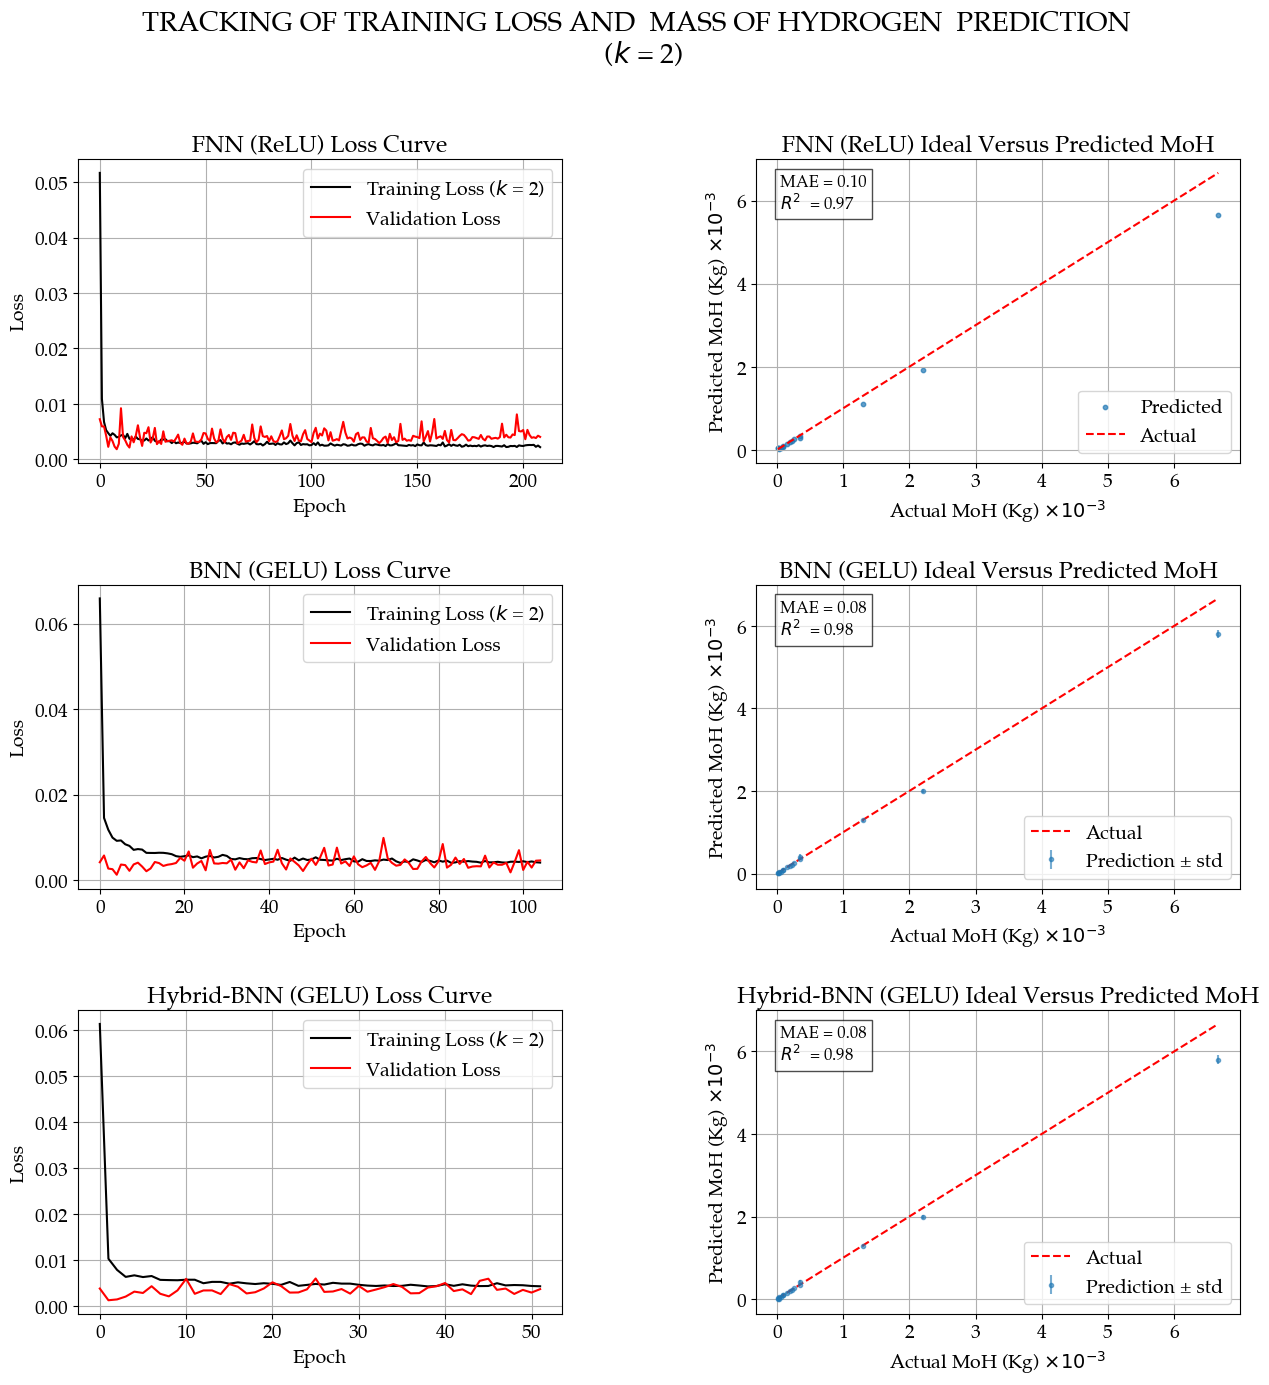

In [24]:
### GRAPHICAL PLOTS FOR IDEAL VERSUS PREDICTED VALUES & TRAINING AND VALIDATION LOSS TRACKING (COMBINED) ###
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt

font_path = "/content/Palatia.ttf"

# Add font and get the font name
fm.fontManager.addfont(font_path)
prop = fm.FontProperties(fname=font_path)
font_name = prop.get_name()

# Set globally
plt.rcParams['font.family'] = font_name

# You can also set other font properties globally
plt.rcParams['font.size'] = 14
plt.rcParams['font.weight'] = 'normal'
# Explicitly disable LaTeX rendering
plt.rcParams['text.usetex'] = False


## Defining the selected Neural Network Model and their corresponding Activation Functions ##
models = ['FNN', 'BNN', 'Hybrid-BNN']
activations = {'FNN': 'ReLU', 'BNN': 'GELU', 'Hybrid-BNN': 'GELU'}

## Defining the selected neural network model training & validation losses dictionaries as well as their corresponding activation functions ##
train_losses_dict = {
    'FNN': fnn_train_losses,
    'BNN': bnn_train_losses,
    'Hybrid-BNN': hybrid_train_losses
}

val_losses_dict = {
    'FNN': fnn_val_losses,
    'BNN': bnn_val_losses,
    'Hybrid-BNN': hybrid_val_losses
}

results_dict = {
    'FNN': fnn_results,
    'BNN': bnn_results,
    'Hybrid-BNN': bnn_results
}


## Defining the Graphical Plot Configurations ##
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(15, 15))
plt.subplots_adjust(wspace=0.4, hspace=0.4)
fig.suptitle("TRACKING OF TRAINING LOSS AND  MASS OF HYDROGEN  PREDICTION \n ($k$ = 2)", fontsize=20)

for idx, model in enumerate(models):
    act = activations[model]


    ## Graphical Plots 1: Training vs Validation Loss ##
    ax1 = axes[idx, 0]
    ax1.plot(train_losses_dict[model][act], label=r'Training Loss ($k$ = 2)',color='k')
    ax1.plot(val_losses_dict[model][act], label='Validation Loss',color='r')
    # ax1.ticklabel_format(axis='both', style='sci', scilimits=( -3, -3), useMathText=True)
    ax1.set_title(f'{model} ({act}) Loss Curve')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.legend()
    ax1.grid(True)

    ## Graphical Plots 2: True vs Predicted MoH ##
    ax2 = axes[idx, 1]
    y_true = results_dict[model][act]['y_true']
    y_pred = results_dict[model][act]['y_pred']

    ## Adding Errors Bars for uncertainty for the Hybrid-BNN ##

    if 'y_std' in results_dict[model][act]:
        y_std = results_dict[model][act]['y_std']
        ax2.errorbar(y_true.flatten(), y_pred.flatten(), yerr=y_std.flatten(), fmt='o', markersize=3, alpha=0.6, label='Prediction ± std')
    else:
        ax2.scatter(y_true, y_pred, s=10, alpha=0.7, label='Predicted')

    ## Diagonal line for the Ideal versus Predicted MoH Graphical Plots ##

    ax2.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'r--', label='Actual')

    ## Annotating the Metrics on the MoH Graphical Plots ##
    mae = results_dict[model][act]['mae']
    r2 = results_dict[model][act]['r2']
    ax2.text(0.05, 0.95,
         (f'MAE = {mae:.2f}\n'
          rf'$R^2$  = {r2:.2f}'),
         transform=ax2.transAxes,
         fontsize=12, verticalalignment='top',
         bbox=dict(facecolor='white', alpha=0.7))


    ax2.set_title(f'{model} ({act}) Ideal Versus Predicted MoH')
    ax2.set_xlabel(r'Actual MoH (Kg) $\times 10^{-3}$')
    ax2.set_ylabel(r'Predicted MoH (Kg) $\times 10^{-3}$')
    # ax2.set_ylabel('Predicted MoH (Kg) $\times$ 10$^-3$$')
    ax2.legend()
    ax2.grid(True)

## Final Layout Adjustments for the Graphical Plots ##
# plt.tight_layout(rect=[0, 0.03, 1, 0.97])
plt.savefig("Model_Comparison_Plots_2.png", dpi=600)
plt.show()

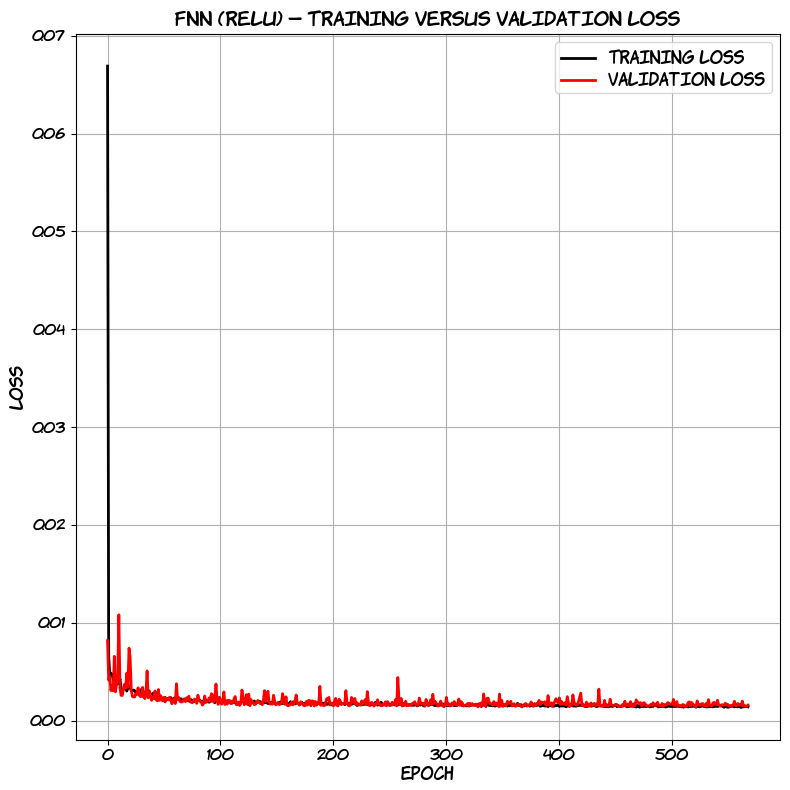

Saved: Individual_Model_Plots/fnn_Loss_Plot.png


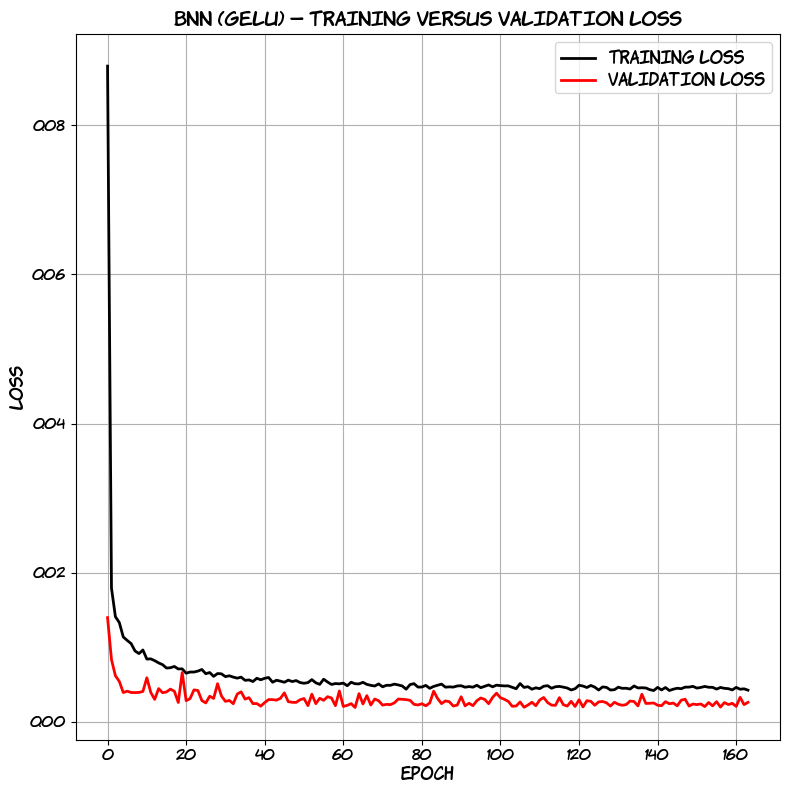

Saved: Individual_Model_Plots/bnn_Loss_Plot.png


/tmp/ipython-input-3885257814.py:23: UserWarning: Glyph 45 (-) missing from font(s) Komika Hand.
  plt.tight_layout()
/tmp/ipython-input-3885257814.py:26: UserWarning: Glyph 45 (-) missing from font(s) Komika Hand.
  plt.savefig(filename, dpi=600)


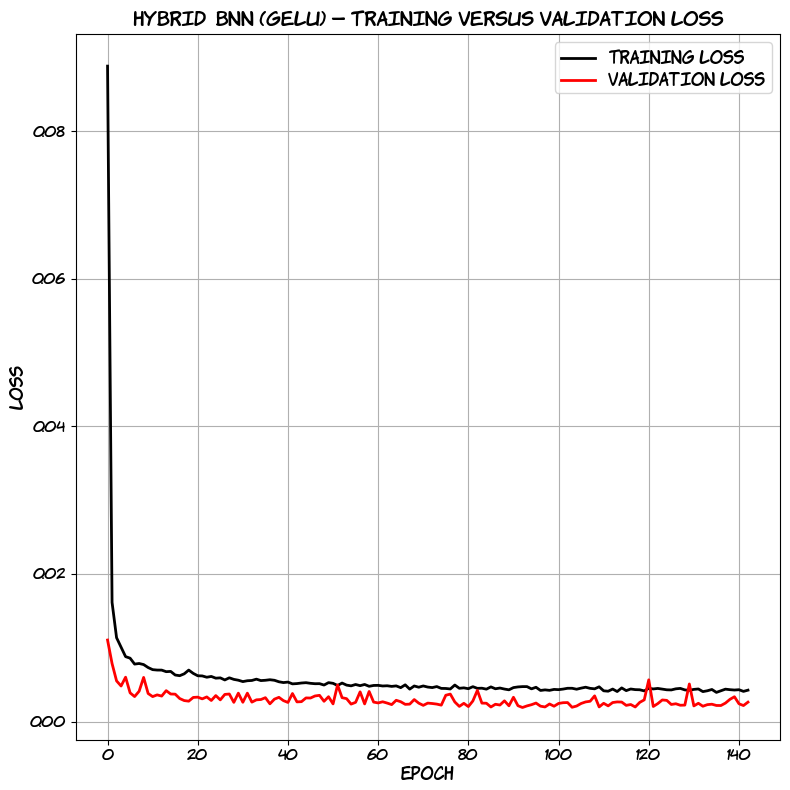

Saved: Individual_Model_Plots/hybrid_bnn_Loss_Plot.png


/tmp/ipython-input-3885257814.py:60: UserWarning: Glyph 178 (\N{SUPERSCRIPT TWO}) missing from font(s) Komika Hand.
  plt.tight_layout()
/tmp/ipython-input-3885257814.py:63: UserWarning: Glyph 178 (\N{SUPERSCRIPT TWO}) missing from font(s) Komika Hand.
  plt.savefig(filename, dpi=600)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 178 (\N{SUPERSCRIPT TWO}) missing from font(s) Komika Hand.
  fig.canvas.print_figure(bytes_io, **kw)


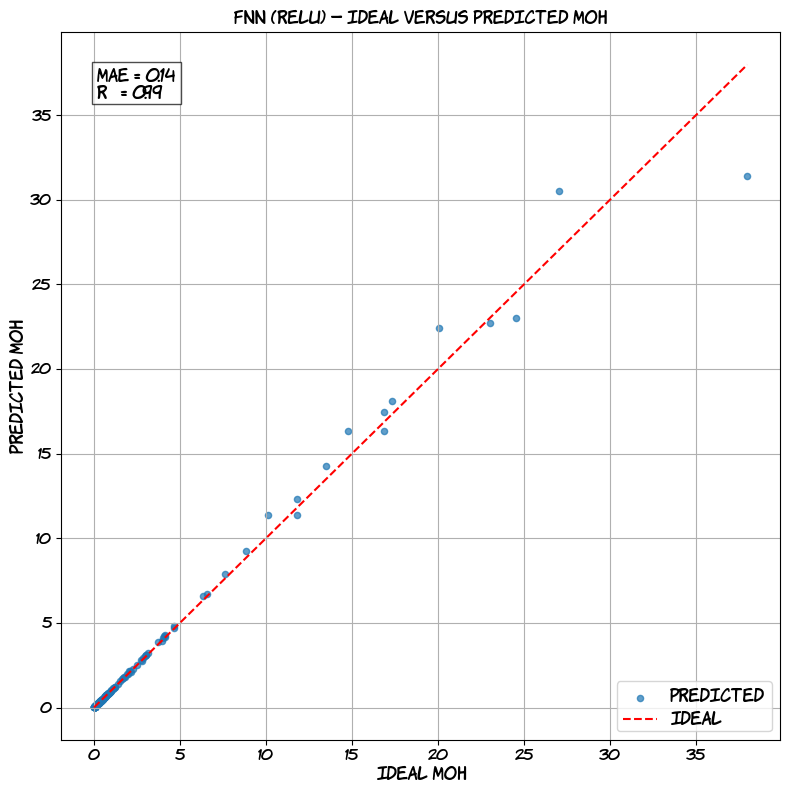

Saved: Individual_Model_Plots/fnn_Prediction_Plot.png


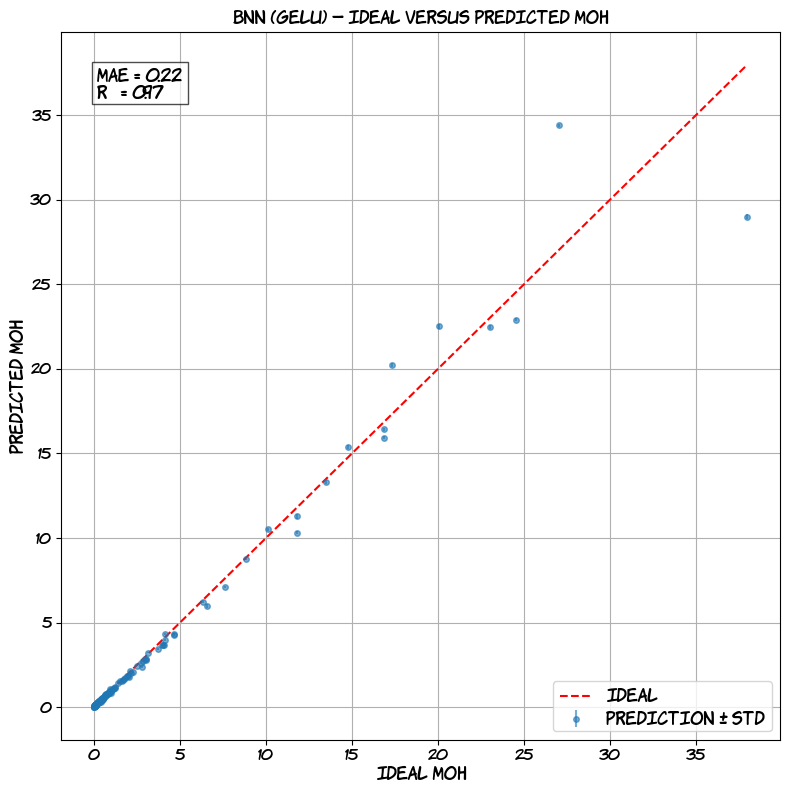

Saved: Individual_Model_Plots/bnn_Prediction_Plot.png


/tmp/ipython-input-3885257814.py:60: UserWarning: Glyph 45 (-) missing from font(s) Komika Hand.
  plt.tight_layout()
/tmp/ipython-input-3885257814.py:63: UserWarning: Glyph 45 (-) missing from font(s) Komika Hand.
  plt.savefig(filename, dpi=600)


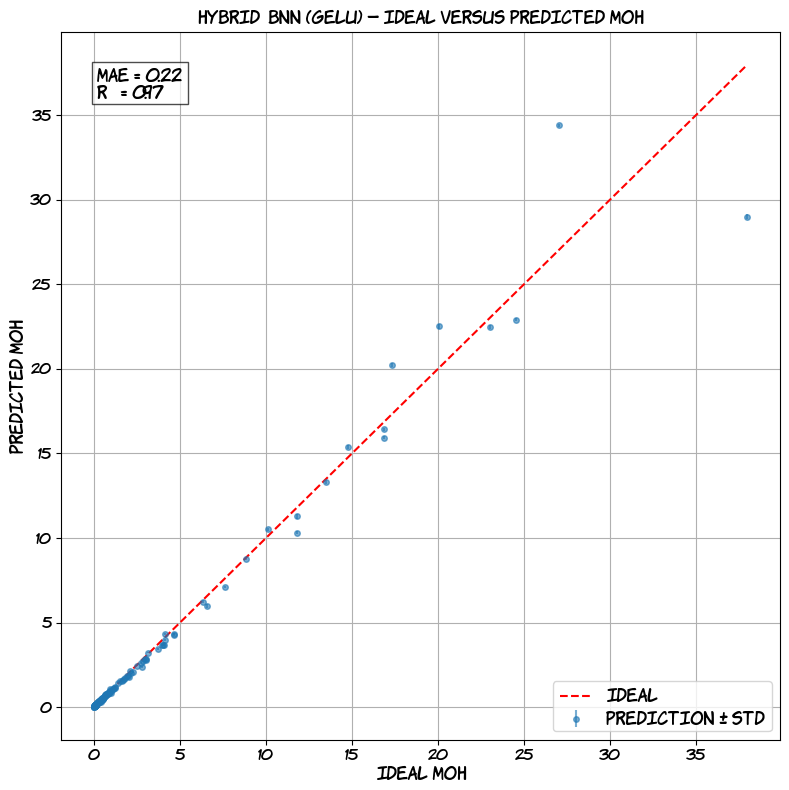

Saved: Individual_Model_Plots/hybrid_bnn_Prediction_Plot.png


In [ ]:
### GRAPHICAL PLOTS FOR IDEAL VERSUS PREDICTED VALUES & TRAINING AND VALIDATION LOSS TRACKING (INDIVIDUAL) ###

## Creating a Directory doe Saving the Graphical Plots ##
os.makedirs("Individual_Model_Plots", exist_ok=True)

## Defining the Models and Activation Mappings  ##
models = ['FNN', 'BNN', 'Hybrid-BNN']
activations = {'FNN': 'ReLU', 'BNN': 'GELU', 'Hybrid-BNN': 'GELU'}


## Defining the Training and Validation Loss Plots  ##
for model in models:
    act = activations[model]

    plt.figure(figsize=(8, 8))
    plt.plot(train_losses_dict[model][act], label="Training Loss", linewidth=2, color='k')
    plt.plot(val_losses_dict[model][act], label="Validation Loss", linewidth=2, color='r')
    plt.title(f"{model} ({act}) — Training Versus Validation Loss", fontsize=14)
    plt.xlabel("Epoch", fontsize=12)
    plt.ylabel("Loss", fontsize=12)
    plt.legend(fontsize=12)
    plt.grid(True)
    plt.tight_layout()

    filename = f"Individual_Model_Plots/{model.lower().replace('-', '_')}_Loss_Plot.png"
    plt.savefig(filename, dpi=600)
    plt.show()
    print(f"Saved: {filename}")

## Defining the Graphical Plots for each model:True Versus Predicted MoH Plots  ##
for model in models:
    act = activations[model]
    y_true = results_dict[model][act]["y_true"]
    y_pred = results_dict[model][act]["y_pred"]

    plt.figure(figsize=(8, 8))

    if "y_std" in results_dict[model][act]:
        y_std = results_dict[model][act]["y_std"]
        plt.errorbar(y_true.flatten(), y_pred.flatten(), yerr=y_std.flatten(),
                     fmt='o', markersize=4, alpha=0.6, label="Prediction ± std")
    else:
        plt.scatter(y_true, y_pred, s=20, alpha=0.7, label="Predicted")

     ## Plotting the Reference Line ##
    plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()],
             'r--', label="Ideal")

    ## Annotating the Metrics ##
    mae = results_dict[model][act]["mae"]
    r2 = results_dict[model][act]["r2"]
    plt.text(0.05, 0.95, f"MAE = {mae:.2f}\nR² = {r2:.2f}", transform=plt.gca().transAxes,
             fontsize=12, verticalalignment="top", bbox=dict(facecolor="white", alpha=0.7))

    plt.title(f"{model} ({act}) — Ideal Versus Predicted MoH", fontsize=12)
    plt.xlabel("Ideal MoH", fontsize=12)
    plt.ylabel("Predicted MoH", fontsize=12)
    plt.legend(fontsize=12)
    plt.grid(True)
    plt.tight_layout()

    filename = f"Individual_Model_Plots/{model.lower().replace('-', '_')}_Prediction_Plot.png"
    plt.savefig(filename, dpi=600)
    plt.show()
    print(f"Saved: {filename}")

In [ ]:
### INDIVIDUAL GRAPHICAL PLOTS ###
y_true = y_test_raw.flatten()
y_pred_fnn = fnn_results['ReLU']['y_pred'].flatten()
y_pred_bnn = bnn_results['GELU']['y_pred'].flatten()
y_pred_hybrid = hybrid_results['GELU']['y_pred'].flatten()

## Defining Plotting Function with the metrics ##
def plot_pred_vs_true(y_true, y_pred, model_name, color='blue'):
    r2 = r2_score(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)

    plt.figure(figsize=(8,8))
    plt.scatter(y_true, y_pred, color=color, alpha=0.8, edgecolor='k')
    plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'r--')
    plt.xlabel('Actual MoH (g)')
    plt.ylabel('Predicted MoH (g)')
    plt.title(f'{model_name} — R²={r2:.3f}, RMSE={rmse:.3f}')
    plt.grid(True)
    plt.tight_layout()
    plt.savefig('HYBRID_BNN_PLOT_MOH', dpi=600)
    plt.show()
## Graphical Plots for Each Model ##
# plot_pred_vs_true(y_true, y_pred_fnn, "FNN", color='dodgerblue')
# plot_pred_vs_true(y_true, y_pred_bnn, "BNN", color='seagreen')
# plot_pred_vs_true(y_true, y_pred_hybrid, "HybridBNN", color='darkorange')